# 05 - Sales Forecasting

Train regression models to forecast **monthly sales revenue** using the engineered monthly dataset. This notebook uses a **chronological train/test split** - the model never sees future months during training.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import matplotlib.pyplot as plt

import data_loader, feature_engineering, train_model, visualization

In [2]:
df = data_loader.load_processed_data()
df = feature_engineering.engineer_all_features(df)
monthly_df = feature_engineering.build_monthly_forecasting_dataset(df)
monthly_df.shape

(45, 12)

## Chronological train/test split

Because this is a forecasting problem, the data is **not** randomly shuffled. The first 80% of months are used for training and the last 20% for testing, so future observations never influence the training process.

In [3]:
train, test = train_model.chronological_split(monthly_df, test_size=0.2)
print('Train months:', len(train), '| Test months:', len(test))
print('Train range:', train['Order Date'].min(), '->', train['Order Date'].max())
print('Test range :', test['Order Date'].min(), '->', test['Order Date'].max())

Train months: 36 | Test months: 9
Train range: 2014-04-01 00:00:00 -> 2017-03-01 00:00:00
Test range : 2017-04-01 00:00:00 -> 2017-12-01 00:00:00


## Train and evaluate all candidate models

In [4]:
comparison_df, fitted_models, predictions, train, test = train_model.train_and_compare(monthly_df)
comparison_df

,Model,MAE,RMSE,R2
0,Linear Regression,4275.471692,6248.936240,0.937311
1,Decision Tree,11582.980893,13947.465029,0.687700
3,Gradient Boosting,11510.085477,14785.476739,0.649044
2,Random Forest,11229.020260,15088.968817,0.634489


## Actual vs Predicted Sales (best model)

Best model: Linear Regression


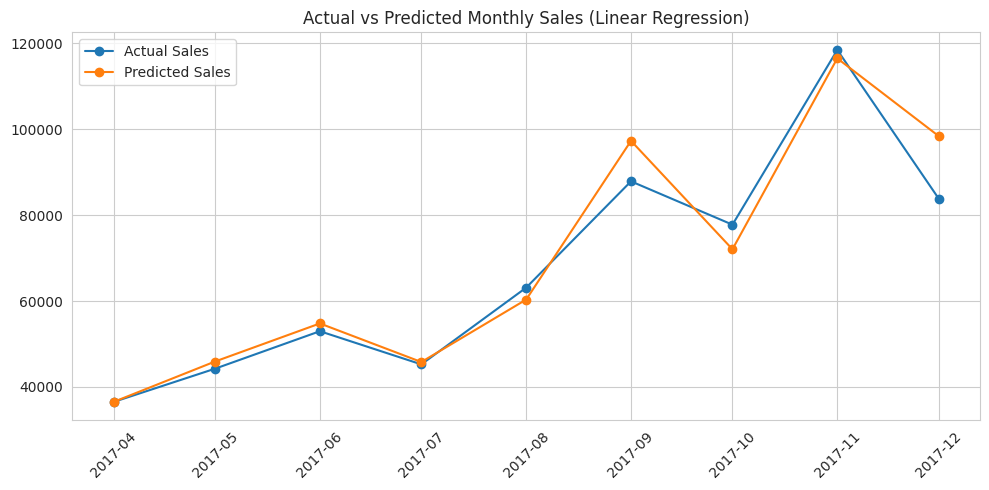

In [5]:
best_name = train_model.select_best_model(comparison_df)
print('Best model:', best_name)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(test['Order Date'], test['Monthly_Sales'], marker='o', label='Actual Sales')
ax.plot(test['Order Date'], predictions[best_name], marker='o', label='Predicted Sales')
ax.set_title(f'Actual vs Predicted Monthly Sales ({best_name})')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
visualization.plot_actual_vs_predicted(
    test['Order Date'], test['Monthly_Sales'], predictions[best_name], best_name
)

## Metric definitions

- **MAE (Mean Absolute Error):** average absolute difference between actual and predicted sales, in the same currency units as `Sales`. Easy to interpret, treats all errors equally.
- **RMSE (Root Mean Squared Error):** similar to MAE but squares errors before averaging, so it penalizes large errors more heavily.
- **R² (Coefficient of Determination):** proportion of the variance in monthly sales that is explained by the model; 1.0 is a perfect fit, 0 means the model is no better than always predicting the mean.